# Experiment 3 — MobileNetV2 Transfer Learning + Fine-Tuning

This is the strongest experiment.

Stage 1:
- MobileNetV2 pretrained on ImageNet
- Freeze the pretrained base
- Train a new classification head

Stage 2:
- Unfreeze the top 30 layers
- Fine-tune with a very small learning rate

In [7]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import seaborn as sns

from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from sklearn.metrics import classification_report, confusion_matrix

print("TensorFlow:", tf.__version__)

TensorFlow: 2.10.0


In [8]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

In [9]:
# =========================
# 1. CONFIGURATION
# =========================

# Your dataset path
DATASET_PATH = r"C:\Users\Rajat\Desktop\Vehicles"

SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)

print("Dataset path:", DATASET_PATH)
print("Exists:", os.path.exists(DATASET_PATH))

if not os.path.exists(DATASET_PATH):
    raise FileNotFoundError(
        f"Dataset not found at: {DATASET_PATH}\n"
        "Please change DATASET_PATH to the folder containing your class folders."
    )

Dataset path: C:\Users\Rajat\Desktop\Vehicles
Exists: True


## 2. Data Loaders

In [10]:
IMG_SIZE = 224
BATCH_SIZE = 32

train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    validation_split=0.2,
    rotation_range=15,
    width_shift_range=0.10,
    height_shift_range=0.10,
    zoom_range=0.15,
    shear_range=0.10,
    horizontal_flip=True,
    fill_mode="nearest"
)

val_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    validation_split=0.2
)

train_data = train_datagen.flow_from_directory(
    DATASET_PATH,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    subset="training",
    shuffle=True,
    seed=SEED
)

val_data = val_datagen.flow_from_directory(
    DATASET_PATH,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    subset="validation",
    shuffle=False
)

num_classes = train_data.num_classes

print("Number of classes:", num_classes)
print("Classes:", train_data.class_indices)

Found 5060 images belonging to 6 classes.
Found 1264 images belonging to 6 classes.
Number of classes: 6
Classes: {'Auto Rickshaws': 0, 'Bikes': 1, 'Cars': 2, 'Motorcycles': 3, 'human': 4, 'unknown': 5}


## 3. MobileNetV2 Model

In [11]:
base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

base_model.trainable = False

model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(num_classes, activation="softmax")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 mobilenetv2_1.00_224 (Funct  (None, 7, 7, 1280)       2257984   
 ional)                                                          
                                                                 
 global_average_pooling2d_1   (None, 1280)             0         
 (GlobalAveragePooling2D)                                        
                                                                 
 dense_2 (Dense)             (None, 128)               163968    
                                                                 
 dropout_1 (Dropout)         (None, 128)               0         
                                                                 
 dense_3 (Dense)             (None, 6)                 774       
                                                                 
Total params: 2,422,726
Trainable params: 164,742
Non-

## 4. Stage 1 — Train Classification Head

In [12]:
early_stop_stage1 = EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True,
    verbose=1
)

reduce_lr_stage1 = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

checkpoint_stage1 = ModelCheckpoint(
    "experiment3_stage1_best.keras",
    monitor="val_accuracy",
    save_best_only=True,
    mode="max",
    verbose=1
)

history_stage1 = model.fit(
    train_data,
    validation_data=val_data,
    epochs=15,
    callbacks=[
        early_stop_stage1,
        reduce_lr_stage1,
        checkpoint_stage1
    ]
)

Epoch 1/15
159/159 [==============================] - ETA: 0s - loss: 0.1784 - accuracy: 0.9401
Epoch 1: val_accuracy improved from -inf to 0.98259, saving model to experiment3_stage1_best.keras
159/159 [==============================] - 60s 369ms/step - loss: 0.1784 - accuracy: 0.9401 - val_loss: 0.0501 - val_accuracy: 0.9826 - lr: 0.0010
Epoch 2/15
159/159 [==============================] - ETA: 0s - loss: 0.0643 - accuracy: 0.9804
Epoch 2: val_accuracy improved from 0.98259 to 0.98655, saving model to experiment3_stage1_best.keras
159/159 [==============================] - 56s 350ms/step - loss: 0.0643 - accuracy: 0.9804 - val_loss: 0.0449 - val_accuracy: 0.9866 - lr: 0.0010
Epoch 3/15
159/159 [==============================] - ETA: 0s - loss: 0.0417 - accuracy: 0.9856
Epoch 3: val_accuracy improved from 0.98655 to 0.98892, saving model to experiment3_stage1_best.keras
159/159 [==============================] - 65s 407ms/step - loss: 0.0417 - accuracy: 0.9856 - val_loss: 0.0381 - va

## 5. Stage 2 — Fine-Tune Top 30 Layers

In [13]:
base_model.trainable = True

# Freeze earlier layers.
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Keep BatchNormalization layers frozen for stable fine-tuning.
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("Trainable layers:")
for layer in base_model.layers:
    if layer.trainable:
        print(layer.name)

Trainable layers:
block_14_expand
block_14_expand_relu
block_14_depthwise
block_14_depthwise_relu
block_14_project
block_14_add
block_15_expand
block_15_expand_relu
block_15_depthwise
block_15_depthwise_relu
block_15_project
block_15_add
block_16_expand
block_16_expand_relu
block_16_depthwise
block_16_depthwise_relu
block_16_project
Conv_1
out_relu


In [14]:
early_stop_stage2 = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

reduce_lr_stage2 = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=2,
    min_lr=1e-7,
    verbose=1
)

checkpoint_stage2 = ModelCheckpoint(
    "experiment3_best.keras",
    monitor="val_accuracy",
    save_best_only=True,
    mode="max",
    verbose=1
)

history_stage2 = model.fit(
    train_data,
    validation_data=val_data,
    epochs=15,
    callbacks=[
        early_stop_stage2,
        reduce_lr_stage2,
        checkpoint_stage2
    ]
)

Epoch 1/15
159/159 [==============================] - ETA: 0s - loss: 0.0266 - accuracy: 0.9913
Epoch 1: val_accuracy improved from -inf to 0.99367, saving model to experiment3_best.keras
159/159 [==============================] - 47s 283ms/step - loss: 0.0266 - accuracy: 0.9913 - val_loss: 0.0275 - val_accuracy: 0.9937 - lr: 1.0000e-05
Epoch 2/15
159/159 [==============================] - ETA: 0s - loss: 0.0154 - accuracy: 0.9949
Epoch 2: val_accuracy did not improve from 0.99367
159/159 [==============================] - 44s 274ms/step - loss: 0.0154 - accuracy: 0.9949 - val_loss: 0.0293 - val_accuracy: 0.9937 - lr: 1.0000e-05
Epoch 3/15
159/159 [==============================] - ETA: 0s - loss: 0.0160 - accuracy: 0.9947
Epoch 3: ReduceLROnPlateau reducing learning rate to 1.9999999494757505e-06.

Epoch 3: val_accuracy did not improve from 0.99367
159/159 [==============================] - 44s 277ms/step - loss: 0.0160 - accuracy: 0.9947 - val_loss: 0.0313 - val_accuracy: 0.9913 - lr

## 6. Evaluation

40/40 [==============================] - 6s 142ms/step - loss: 0.0275 - accuracy: 0.9937
Final Validation Loss: 0.0275
Final Validation Accuracy: 99.37%


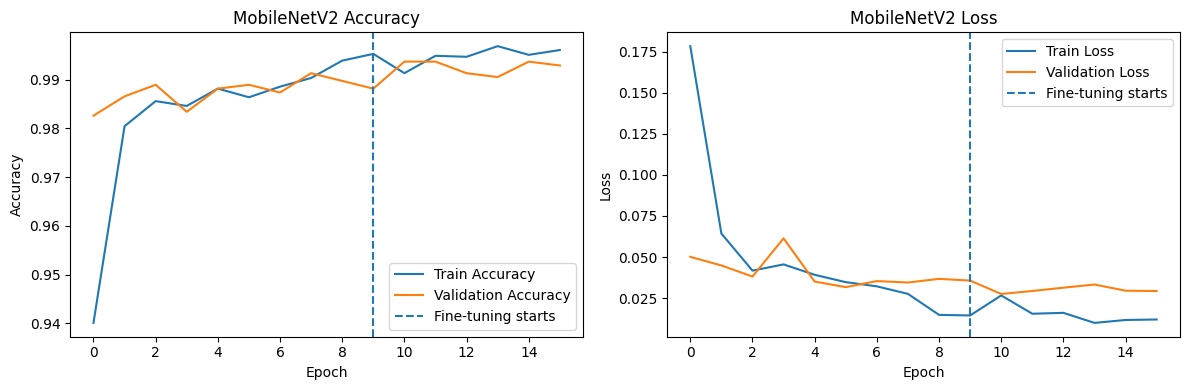

40/40 [==============================] - 6s 135ms/step

Classification Report:
                precision    recall  f1-score   support

Auto Rickshaws     0.9691    0.9812    0.9752       160
         Bikes     1.0000    1.0000    1.0000       160
          Cars     1.0000    0.9810    0.9904       158
   Motorcycles     0.9875    0.9875    0.9875       160
         human     0.9977    1.0000    0.9989       440
       unknown     1.0000    1.0000    1.0000       186

      accuracy                         0.9937      1264
     macro avg     0.9924    0.9916    0.9920      1264
  weighted avg     0.9937    0.9937    0.9937      1264



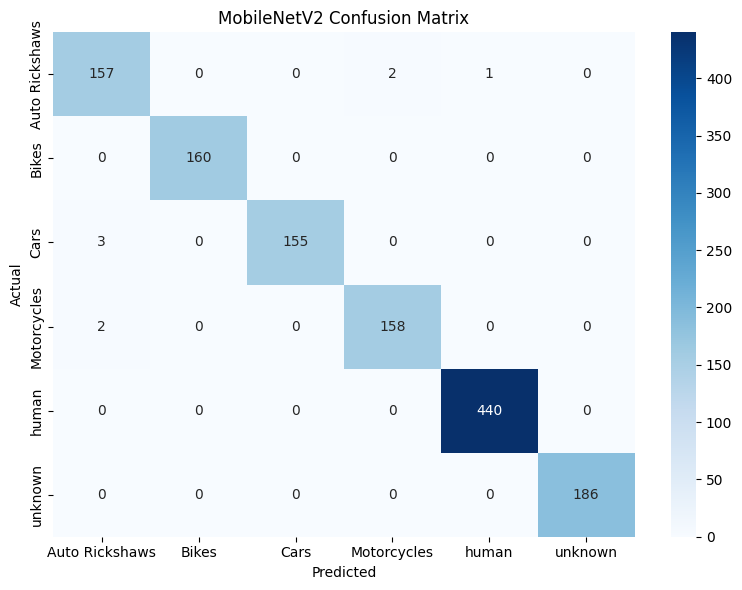

In [15]:
val_loss, val_accuracy = model.evaluate(val_data, verbose=1)

print(f"Final Validation Loss: {val_loss:.4f}")
print(f"Final Validation Accuracy: {val_accuracy * 100:.2f}%")

# Combine Stage 1 and Stage 2 histories
acc = history_stage1.history["accuracy"] + history_stage2.history["accuracy"]
val_acc = history_stage1.history["val_accuracy"] + history_stage2.history["val_accuracy"]

loss = history_stage1.history["loss"] + history_stage2.history["loss"]
val_loss_history = history_stage1.history["val_loss"] + history_stage2.history["val_loss"]

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(acc, label="Train Accuracy")
plt.plot(val_acc, label="Validation Accuracy")
plt.axvline(
    len(history_stage1.history["accuracy"]) - 1,
    linestyle="--",
    label="Fine-tuning starts"
)
plt.title("MobileNetV2 Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(loss, label="Train Loss")
plt.plot(val_loss_history, label="Validation Loss")
plt.axvline(
    len(history_stage1.history["loss"]) - 1,
    linestyle="--",
    label="Fine-tuning starts"
)
plt.title("MobileNetV2 Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

val_data.reset()
pred_probs = model.predict(val_data, verbose=1)

y_pred = np.argmax(pred_probs, axis=1)
y_true = val_data.classes
class_names = list(val_data.class_indices.keys())

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4
))

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=class_names,
    yticklabels=class_names,
    cmap="Blues"
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("MobileNetV2 Confusion Matrix")
plt.tight_layout()
plt.show()

In [16]:
model.save("experiment3_final_mobilenetv2.keras")
print("Saved: experiment3_final_mobilenetv2.keras")

Saved: experiment3_final_mobilenetv2.keras


In [17]:
import cv2
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import load_model
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

# ============================================
# 1. LOAD YOUR TRAINED MODEL
# ============================================

MODEL_PATH = "experiment3_final_mobilenetv2.keras"

model = load_model(MODEL_PATH)

print("Model loaded successfully!")


# ============================================
# 2. CLASS NAMES
# ============================================

class_names = [
    "Auto Rickshaws",
    "Bikes",
    "Cars",
    "Motorcycles",
    "human",
    "unknown"
]

print("Classes:", class_names)


# ============================================
# 3. OPEN WEBCAM
# ============================================

cap = cv2.VideoCapture(0)

if not cap.isOpened():
    print("ERROR: Could not open webcam.")
    raise SystemExit


# ============================================
# 4. WEBCAM LOOP
# ============================================

while True:

    ret, frame = cap.read()

    if not ret:
        print("ERROR: Could not read webcam frame.")
        break

    # Flip webcam horizontally for mirror effect
    frame = cv2.flip(frame, 1)

    height, width, _ = frame.shape

    # --------------------------------------------
    # Green detection box
    # --------------------------------------------

    box_size = 350

    x1 = (width - box_size) // 2
    y1 = (height - box_size) // 2

    x2 = x1 + box_size
    y2 = y1 + box_size

    # Crop the region inside the green box
    roi = frame[y1:y2, x1:x2]

    # --------------------------------------------
    # Prepare image for MobileNetV2
    # --------------------------------------------

    img = cv2.resize(roi, (224, 224))

    img = img.astype(np.float32)

    # MobileNetV2 preprocessing
    img = preprocess_input(img)

    # Add batch dimension
    img = np.expand_dims(img, axis=0)

    # --------------------------------------------
    # Prediction
    # --------------------------------------------

    prediction = model.predict(img, verbose=0)

    predicted_index = np.argmax(prediction[0])

    predicted_class = class_names[predicted_index]

    confidence = prediction[0][predicted_index] * 100

    # --------------------------------------------
    # Draw green box
    # --------------------------------------------

    cv2.rectangle(
        frame,
        (x1, y1),
        (x2, y2),
        (0, 255, 0),
        3
    )

    # --------------------------------------------
    # Display prediction
    # --------------------------------------------

    label = f"{predicted_class}: {confidence:.1f}%"

    # Background for text
    cv2.rectangle(
        frame,
        (x1, y1 - 45),
        (x2, y1),
        (0, 255, 0),
        -1
    )

    cv2.putText(
        frame,
        label,
        (x1 + 10, y1 - 12),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.8,
        (0, 0, 0),
        2
    )

    # Instruction
    cv2.putText(
        frame,
        "Place vehicle inside box | Press Q to quit",
        (20, height - 20),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.7,
        (255, 255, 255),
        2
    )

    # --------------------------------------------
    # Show webcam
    # --------------------------------------------

    cv2.imshow("Vehicle Classification", frame)

    # Press Q to quit
    if cv2.waitKey(1) & 0xFF == ord("q"):
        break


# ============================================
# 5. RELEASE WEBCAM
# ============================================

cap.release()
cv2.destroyAllWindows()

Model loaded successfully!
Classes: ['Auto Rickshaws', 'Bikes', 'Cars', 'Motorcycles', 'human', 'unknown']


In [2]:
import cv2
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import load_model
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

# =========================================================
# 1. LOAD TRAINED MODEL
# =========================================================

MODEL_PATH = "experiment3_final_mobilenetv2.keras"

model = load_model(MODEL_PATH)

print("Model loaded successfully!")

# =========================================================
# 2. MODEL CLASS NAMES
# =========================================================

class_names = [
    "Auto Rickshaws",
    "Bikes",
    "Cars",
    "Motorcycles",
    "human",
    "unknown"
]

print("Classes:", class_names)


# =========================================================
# 3. MAP MODEL CLASSES TO PROJECT OUTPUT
# =========================================================

def map_to_project_class(model_class):

    if model_class == "Auto Rickshaws":
        return "AUTO RICKSHAW"

    elif model_class == "Cars":
        return "CAR"

    elif model_class in ["Bikes", "Motorcycles"]:
        return "BIKE"

    elif model_class == "human":
        return "HUMAN"

    elif model_class == "unknown":
        return "UNKNOWN"

    else:
        return "UNKNOWN"


# =========================================================
# 4. OPEN CAMERA
# =========================================================

cap = cv2.VideoCapture(0)

if not cap.isOpened():
    print("ERROR: Could not open camera.")
    exit()

print("Camera started.")
print("Press 'q' to quit.")


# =========================================================
# 5. LIVE PREDICTION
# =========================================================

while True:

    ret, frame = cap.read()

    if not ret:
        print("ERROR: Could not read frame.")
        break

    # Mirror effect
    frame = cv2.flip(frame, 1)

    # Get frame dimensions
    height, width, _ = frame.shape


    # =====================================================
    # PREPARE IMAGE FOR MOBILENETV2
    # =====================================================

    img = cv2.resize(frame, (224, 224))

    # OpenCV uses BGR → convert to RGB
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    img = img.astype(np.float32)

    # MobileNetV2 preprocessing
    img = preprocess_input(img)

    # Add batch dimension
    img = np.expand_dims(img, axis=0)


    # =====================================================
    # PREDICTION
    # =====================================================

    predictions = model.predict(img, verbose=0)

    predicted_index = np.argmax(predictions[0])

    confidence = predictions[0][predicted_index]

    model_class = class_names[predicted_index]

    project_class = map_to_project_class(model_class)


    # =====================================================
    # GREEN BORDER
    # =====================================================

    cv2.rectangle(
        frame,
        (5, 5),
        (width - 5, height - 5),
        (0, 255, 0),
        3
    )


    # =====================================================
    # MAIN OUTPUT
    # =====================================================

    text = f"{project_class} ({confidence * 100:.1f}%)"

    # Black background for text
    cv2.rectangle(
        frame,
        (15, 15),
        (500, 75),
        (0, 0, 0),
        -1
    )

    cv2.putText(
        frame,
        text,
        (30, 58),
        cv2.FONT_HERSHEY_SIMPLEX,
        1.1,
        (0, 255, 0),
        3
    )


    # =====================================================
    # MODEL PREDICTION
    # =====================================================

    detail = f"Model: {model_class}"

    cv2.putText(
        frame,
        detail,
        (30, 105),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.7,
        (255, 255, 255),
        2
    )


    # =====================================================
    # SHOW CAMERA
    # =====================================================

    cv2.imshow(
        "Project Car - Object Detection",
        frame
    )


    # =====================================================
    # PRESS Q TO EXIT
    # =====================================================

    if cv2.waitKey(1) & 0xFF == ord("q"):
        break


# =========================================================
# 6. RELEASE CAMERA
# =========================================================

cap.release()
cv2.destroyAllWindows()

print("Camera stopped.")

Model loaded successfully!
Classes: ['Auto Rickshaws', 'Bikes', 'Cars', 'Motorcycles', 'human', 'unknown']
Camera started.
Press 'q' to quit.
Camera stopped.
